In [32]:
from os import listdir
from os.path import isfile, join

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [33]:
path = '/home/barachiel/Documents/LupiNer/Arsene_Lupi-NER/output/'
all_paths = [file for file in listdir(path) if isfile(join(path,file))]
# all_paths

In [34]:
titles = sorted(set([file.split('_norm_')[0] for file in all_paths if '_norm_' in file]))

print("Available titles:")
for i, title in enumerate(titles):
    print(f"{i}: {title}")

def get_models_for_title(title):
    models = ['fr_core_news_lg', 'fr_core_news_md', 'fr_core_news_sm', 'fr_dep_news_trf']
    files_for_title = [f for f in all_paths if title in f and any(model in f for model in models)]
    return files_for_title


selected_title_index = 0
selected_title = titles[selected_title_index]
selected_files = get_models_for_title(selected_title)
print(f"\nSelected title: {selected_title}")
print(f"Files: {selected_files}")

# print(get_models_for_title(titles[4]))

Available titles:
0: 813_(1910,_Lafitte)
1: Arsène_Lupin_(pièce_de_théâtre)
2: Arsène_Lupin_contre_Herlock_Sholmès_(1908)
3: Arsène_Lupin_contre_Herlock_Sholmès_(1914)
4: Arsène_Lupin_gentleman-cambrioleur
5: La_Barre-y-va
6: La_Cagliostro_se_venge
7: La_Comtesse_de_Cagliostro
8: La_Demeure_mystérieuse
9: La_Demoiselle_aux_yeux_verts
10: La_Femme_aux_deux_sourires
11: Le_Bouchon_de_cristal
12: Le_Cabochon_d’émeraude
13: Le_Pardessus_d’Arsène_Lupin
14: Le_Retour_d’Arsène_Lupin
15: Le_Triangle_d’or
16: Les_Confidences_d’Arsène_Lupin
17: Les_Dents_du_tigre
18: Les_Huit_Coups_de_l’horloge
19: Les_Milliards_d’Arsène_Lupin
20: Les_Nouvelles_Aventures_d’Arsène_Lupin
21: L’Aiguille_creuse
22: L’Homme_à_la_peau_de_bique
23: L’Éclat_d’obus_1916
24: L’Île_aux_trente_cercueils
25: Une_aventure_d’Arsène_Lupin
26: Victor,_de_la_Brigade_mondaine

Selected title: 813_(1910,_Lafitte)
Files: ['813_(1910,_Lafitte)_norm_fr_core_news_lg.csv', '813_(1910,_Lafitte)_norm_fr_core_news_md.csv', '813_(1910,_Lafi

In [35]:
df = pd.DataFrame(columns=['entity', 'label', 'model', 'occurrence'])

for i, title in enumerate(titles):
    print(i, title)
    files = get_models_for_title(titles[i])
    for file in files:
        if file.endswith('.csv'):
            data = pd.read_csv(f"{path}{file}", on_bad_lines='skip')
            data = data.rename(columns={'occurence': 'occurrence'})
            model = file.split('.')[0]
            data['model'] = model.split('_fr_')[1]
            df = pd.concat([df, data], ignore_index=True)
df

0 813_(1910,_Lafitte)
1 Arsène_Lupin_(pièce_de_théâtre)
2 Arsène_Lupin_contre_Herlock_Sholmès_(1908)
3 Arsène_Lupin_contre_Herlock_Sholmès_(1914)
4 Arsène_Lupin_gentleman-cambrioleur
5 La_Barre-y-va
6 La_Cagliostro_se_venge
7 La_Comtesse_de_Cagliostro
8 La_Demeure_mystérieuse
9 La_Demoiselle_aux_yeux_verts
10 La_Femme_aux_deux_sourires
11 Le_Bouchon_de_cristal
12 Le_Cabochon_d’émeraude
13 Le_Pardessus_d’Arsène_Lupin
14 Le_Retour_d’Arsène_Lupin
15 Le_Triangle_d’or
16 Les_Confidences_d’Arsène_Lupin
17 Les_Dents_du_tigre
18 Les_Huit_Coups_de_l’horloge
19 Les_Milliards_d’Arsène_Lupin
20 Les_Nouvelles_Aventures_d’Arsène_Lupin
21 L’Aiguille_creuse
22 L’Homme_à_la_peau_de_bique
23 L’Éclat_d’obus_1916
24 L’Île_aux_trente_cercueils
25 Une_aventure_d’Arsène_Lupin
26 Victor,_de_la_Brigade_mondaine


,entity,label,model,occurrence
0,Altenheim,total,core_news_lg,112
1,Altenheim,LOC,core_news_lg,112
2,Doudeville,total,core_news_lg,58
3,Doudeville,LOC,core_news_lg,58
4,Steinweg,total,core_news_lg,42
...,...,...,...,...
24077,pseudo-Lupin,LOC,core_news_sm,1
24078,jardin des Tuileries,total,core_news_sm,1
24079,jardin des Tuileries,LOC,core_news_sm,1
24080,île de Ré,total,core_news_sm,1


In [36]:
df = df.pivot_table(index='entity', columns='model', values='occurrence', aggfunc='sum')
df = df.rename(columns={'core_news_sm': 'small', 'core_news_md': 'medium', 'core_news_lg': 'large'})
df = df[['small', 'medium', 'large']]
# df = df[df['label'] != 'total']
# df = df.rename(columns=({'occurrence': 'total'})).drop(columns=['label', 'model'])
df['total'] = df[['small', 'medium', 'large']].sum(axis=1)
df = df[df['total'] > 100]
df = df.sort_values(by='total', ascending=False)
df

model,small,medium,large,total
entity,,,,
Paris,1098,1078,1076,3252
Florence,566,578,584,1728
Anglais,566,638,522,1726
Enneris,486,338,410,1234
Ganimard,56,324,702,1082
...,...,...,...,...
Bournef,42,40,20,102
Caudebec,34,34,34,102
Edwards,38,28,36,102


In [37]:
df.describe()

model,small,medium,large,total
count,146,145,136,148
unique,80,73,71,97
top,38,50,52,102
freq,7,7,8,8


In [38]:
# Préparer les données pour le tracé
df_plot = df.reset_index()  # entity devient une colonne

# Passage en format long pour seaborn
df_melted = df_plot.melt(id_vars=['entity', 'total'],
                         value_vars=['small', 'medium', 'large'],
                         var_name='model', value_name='occurrence')

# L'ordre des entités est déjà celui du tri (total décroissant)
entity_order = df_plot['entity'].tolist()


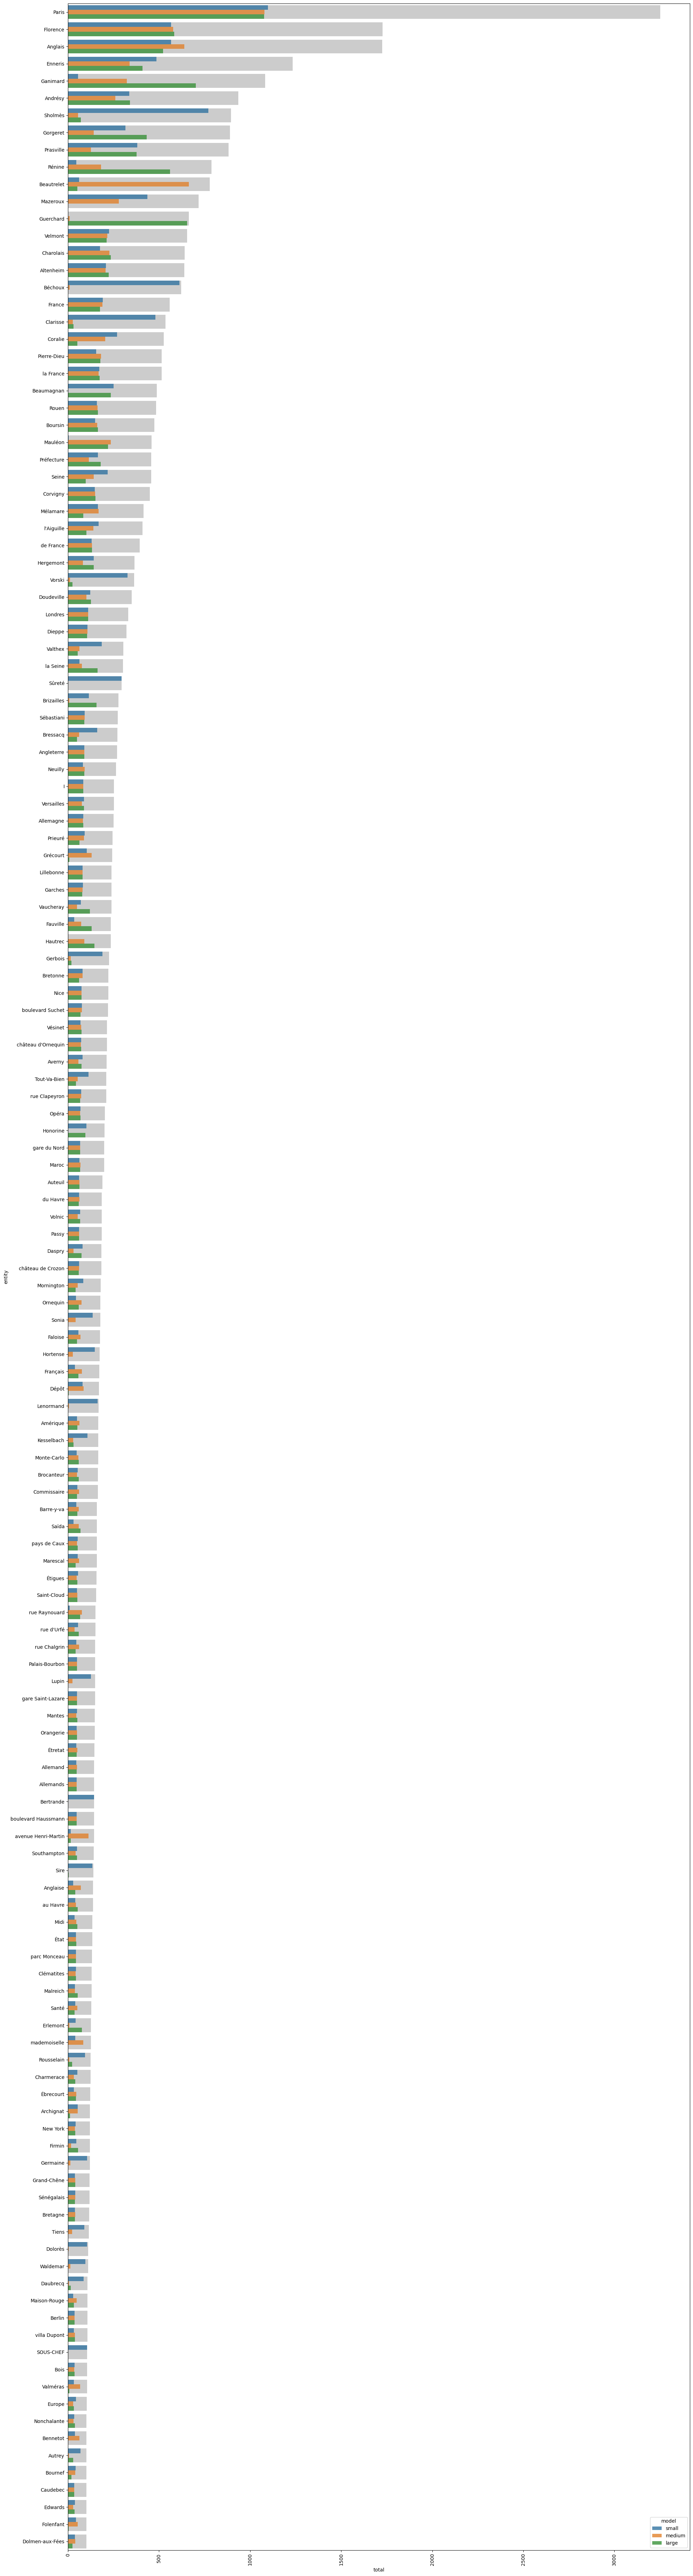

In [39]:
# Tracé
plt.figure(figsize=(20, len(df_plot) * 0.5))  # hauteur proportionnelle
sns.barplot(data=df_plot, y='entity', x='total', color='gray', alpha=0.4,
            zorder=1, order=entity_order)
sns.barplot(data=df_melted, y='entity', x='occurrence', hue='model', alpha=0.8,
            zorder=2, order=entity_order)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()